In [4]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data
iodine = np.array([132.0, 129.0, 120.0, 113.2, 105.0, 92.0, 84.0, 83.2, 88.4, 59.0, 80.0, 81.5, 71.0, 69.2])
cetane = np.array([46.0, 48.0, 51.0, 52.1, 54.0, 52.0, 59.0, 58.7, 61.6, 64.0, 61.4, 54.6, 58.8, 58.0])

# Data Structure with Pandas
df = pd.DataFrame({'cetane': cetane, 'iodine': iodine})

# Linear Regression y~x
model = smf.ols('cetane ~ iodine', data=df).fit()

# Summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 cetane   R-squared:                       0.791
Model:                            OLS   Adj. R-squared:                  0.773
Method:                 Least Squares   F-statistic:                     45.35
Date:                Tue, 06 Oct 2026   Prob (F-statistic):           2.09e-05
Time:                        07:06:48   Log-Likelihood:                -31.971
No. Observations:                  14   AIC:                             67.94
Df Residuals:                      12   BIC:                             69.22
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     75.2124      2.984     25.208      0.0

/Users/hyeongjin/anaconda3/lib/python3.10/site-packages/scipy/stats/_stats_py.py:1736: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=14
  warnings.warn("kurtosistest only valid for n>=20 ... continuing "


In [6]:
# F table
print(sm.stats.anova_lm(model, typ=1))

            df      sum_sq     mean_sq          F    PR(>F)
iodine     1.0  298.254427  298.254427  45.350476  0.000021
Residual  12.0   78.919858    6.576655        NaN       NaN


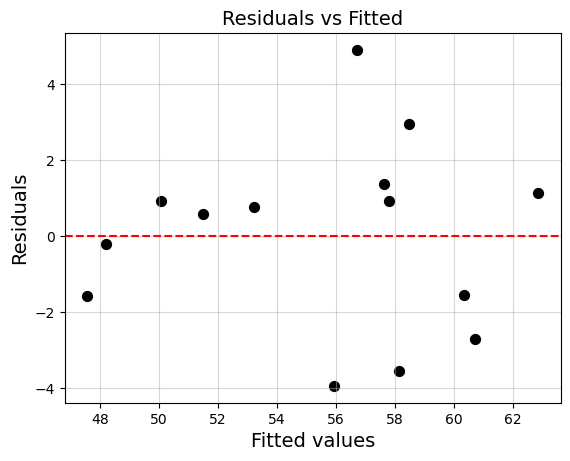

In [51]:
# Residuals vs Fitted
plt.scatter(model.fittedvalues, model.resid, color='black', s=50)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Fitted values', fontsize=14)
plt.ylabel('Residuals', fontsize=14)
plt.title('Residuals vs Fitted', fontsize=14)
plt.grid(True, alpha=0.5)

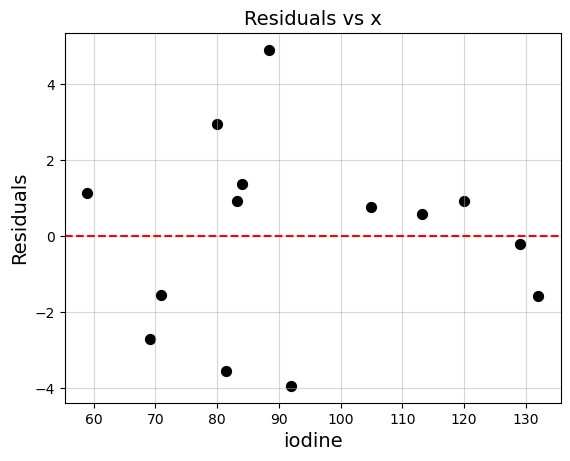

In [52]:
# Residuals vs x
plt.scatter(iodine, model.resid, color='black', s=50)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('iodine', fontsize=14)
plt.ylabel('Residuals', fontsize=14)
plt.title('Residuals vs x', fontsize=14)
plt.grid(True, alpha=0.5)

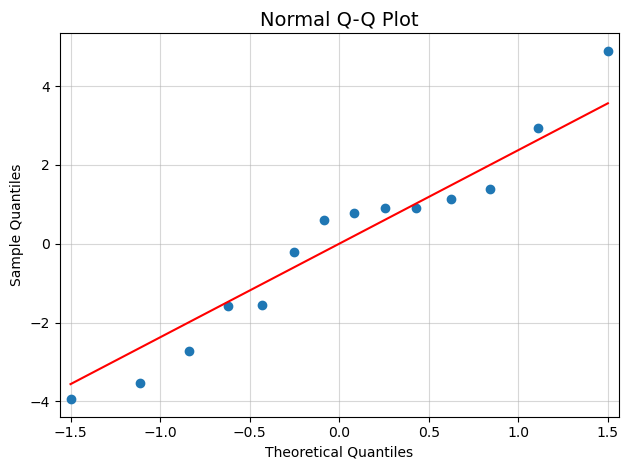

In [53]:
# Q-Q plot
sm.qqplot(model.resid, line='s')
plt.title('Normal Q-Q Plot', fontsize=14)
plt.grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

In [58]:
import copy
x = copy.deepcopy(iodine)
y = copy.deepcopy(cetane)

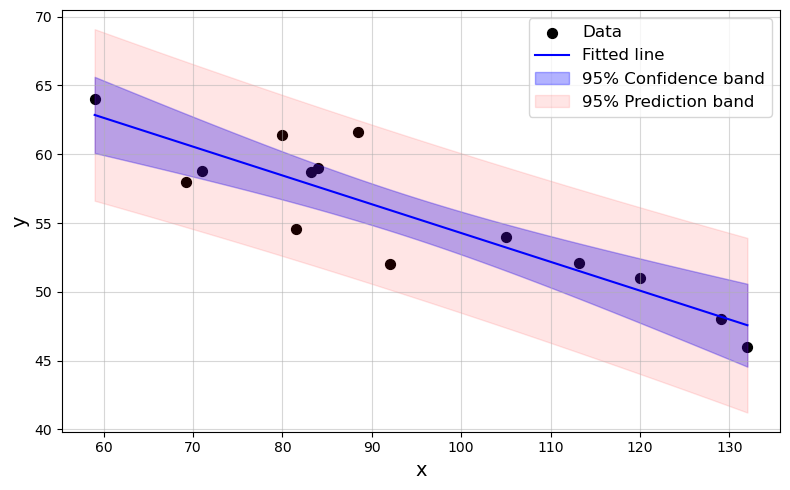

In [59]:
# Linear Regression y~x
model = smf.ols('y ~ x', data=df).fit()

import numpy as np
import matplotlib.pyplot as plt
from statsmodels.sandbox.regression.predstd import wls_prediction_std

# Prediction points
x_pred = np.linspace(x.min(), x.max(), 100)
x_pred_df = pd.DataFrame({'x': x_pred})

# Confidence band (mean response)
predictions = model.get_prediction(x_pred_df)
pred_summary = predictions.summary_frame(alpha=0.05)

# Plot
plt.figure(figsize=(8, 5))
plt.scatter(x, y, color='black', s=50, label='Data')
plt.plot(x_pred, pred_summary['mean'], color='blue', label='Fitted line')

# Confidence band (CI for mean)
plt.fill_between(x_pred, pred_summary['mean_ci_lower'], pred_summary['mean_ci_upper'],
                 alpha=0.3, color='blue', label='95% Confidence band')

# Prediction band (CI for individual observation)
plt.fill_between(x_pred, pred_summary['obs_ci_lower'], pred_summary['obs_ci_upper'],
                 alpha=0.1, color='red', label='95% Prediction band')

plt.xlabel('x', fontsize=14)
plt.ylabel('y', fontsize=14)
plt.legend(fontsize=12)
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()